<a href="https://colab.research.google.com/github/achmadanval/PCVK-2026/blob/main/PCVK_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

Nilai Threshold Otsu: 125


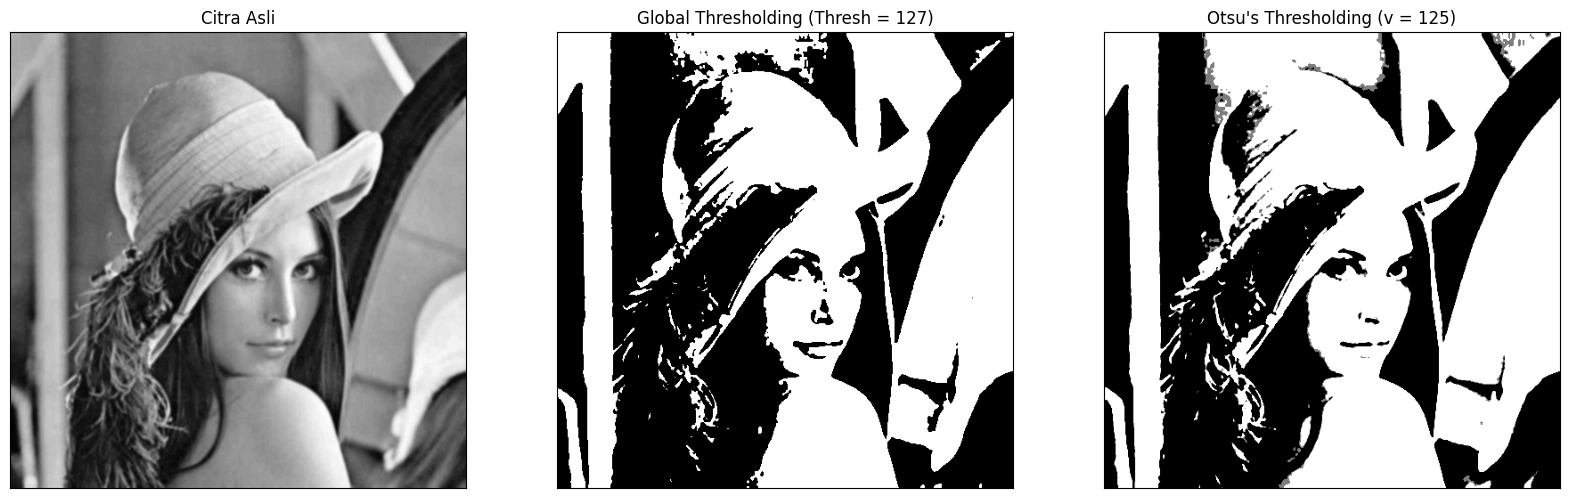

In [ ]:
filename = '/content/drive/MyDrive/lena_lc.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        # Pengaman agar tidak terjadi pembagian dengan nol
        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print("Nilai Threshold Otsu:", final_thresh)

    if final_thresh != -1:
        final_img[gray > final_thresh] = 255
        final_img[gray < final_thresh] = 0

    return final_img, final_thresh

# Eksekusi fungsi Otsu manual
otsu_biner, otsu_thresh = otsu(blur)

# Global Thresholding menggunakan OpenCV
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

# Visualisasi Hasil
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

Hasil binerisasi menjadi hitam total karena nilai per piksel berada di bawah ambang batas (Thresholding) yang menyebabkan nilai tersebut akan langsung di konfersi ke nilai 0 jika berada di bawah nilai threshold.


supaya gambar lena masih terlihat dengan baik menggunakan global thressholding, harus mengubah angka batas ambangnya berada di kisaran 90 - 125.


Nilai Threshold Otsu: 166


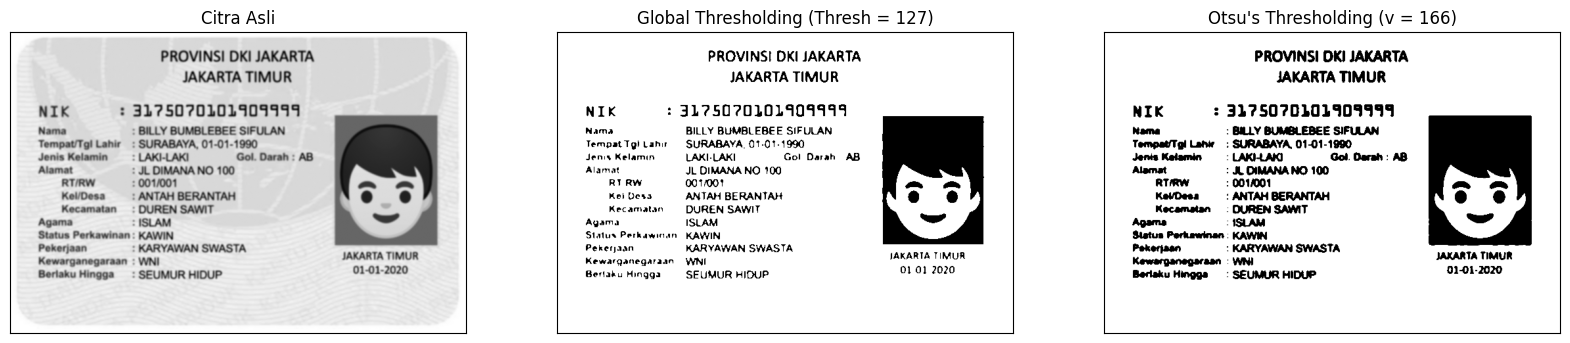

In [ ]:
filename = '/content/drive/MyDrive/ktp_fulan.webp'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        # Pengaman agar tidak terjadi pembagian dengan nol
        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print("Nilai Threshold Otsu:", final_thresh)

    if final_thresh != -1:
        final_img[gray > final_thresh] = 255
        final_img[gray < final_thresh] = 0

    return final_img, final_thresh

# Eksekusi fungsi Otsu manual
otsu_biner, otsu_thresh = otsu(blur)

# Global Thresholding menggunakan OpenCV
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

# Visualisasi Hasil
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

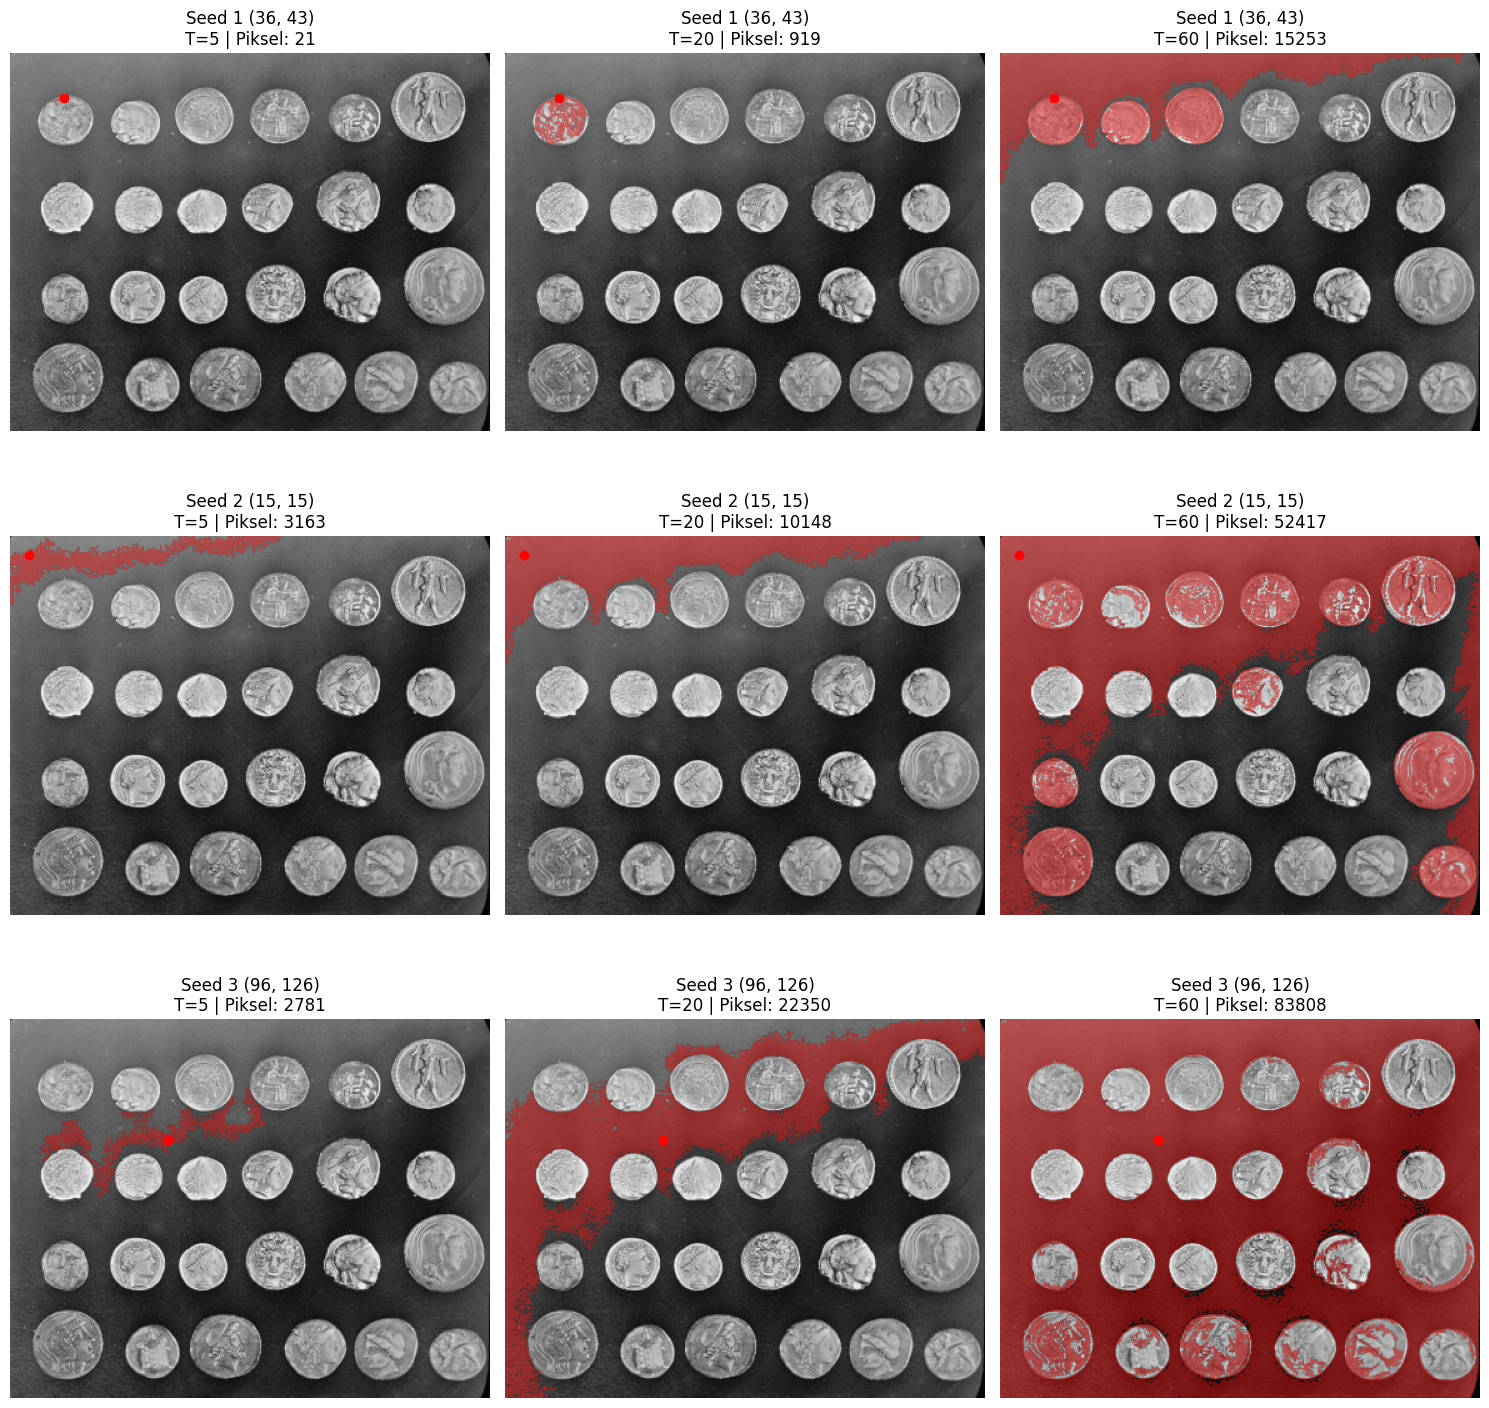

In [ ]:
# 6. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.
from skimage import data
img = data.coins()


# 1. Memuat citra coins dari skimage (grayscale, ukuran 303 x 384)
img = data.coins()

# 2. Menentukan 3 koordinat seed (baris, kolom) sesuai ketentuan:
#    - Seed 1: Di dalam koin (misal: area koin yang terang)
#    - Seed 2: Di latar belakang/background
#    - Seed 3: Tepat di tepi batas koin
seeds = [
    (36, 43),   # Seed 1: Di dalam koin
    (15, 15),   # Seed 2: Di latar belakang
    (96, 126)   # Seed 3: Di tepi koin
]

# Daftar nilai Threshold (T) yang diuji
thresholds = [5, 20, 60]

# 3. Fungsi sederhana untuk Region Growing
def region_growing(image, seed, T):
    rows, cols = image.shape
    segmented = np.zeros((rows, cols), dtype=bool)
    visited = np.zeros((rows, cols), dtype=bool)

    # Ambil nilai intensitas dari titik seed
    seed_intensity = float(image[seed])

    # Menggunakan list sebagai antrean (queue) untuk koordinat (r, c)
    queue = [seed]
    visited[seed] = True

    while queue:
        r, c = queue.pop(0)
        segmented[r, c] = True

        # Periksa 4 tetangga terdekat (atas, bawah, kiri, kanan)
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc

            if 0 <= nr < rows and 0 <= nc < cols and not visited[nr, nc]:
                # Cek kriteria kesamaan berdasarkan selisih intensitas dengan seed awal
                if abs(float(image[nr, nc]) - seed_intensity) <= T:
                    visited[nr, nc] = True
                    queue.append((nr, nc))

    return segmented

# 4. Membuat Visualisasi Grid 3x3 (Baris = Seed, Kolom = T)
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, seed in enumerate(seeds):
    for j, T in enumerate(thresholds):
        # Jalankan algoritma region growing
        res_mask = region_growing(img, seed, T)
        pixel_count = np.sum(res_mask)

        # Tampilkan citra asli dengan tanda titik seed (warna merah)
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].plot(seed[1], seed[0], 'ro', markersize=6) # plot(kolom, baris)

        # Overlay hasil segmentasi dengan warna merah transparan
        overlay = np.zeros((*img.shape, 4), dtype=float)
        overlay[res_mask] = [1, 0, 0, 0.4] # RGBA: Merah dengan transparan 40%
        axes[i, j].imshow(overlay)

        axes[i, j].set_title(f"Seed {i+1} {seed}\nT={T} | Piksel: {pixel_count}")
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

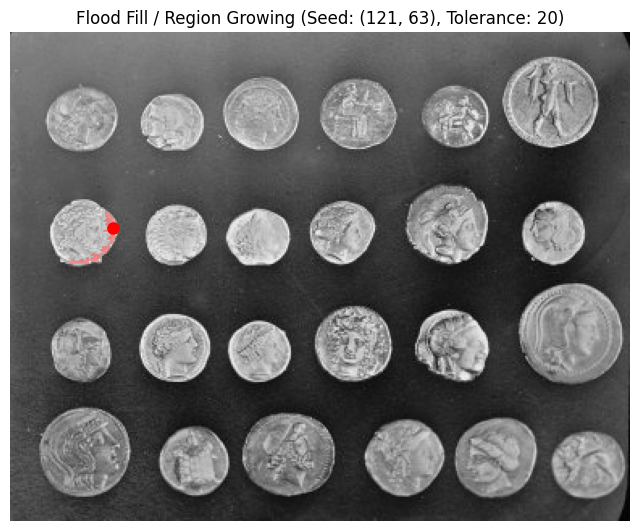

In [ ]:
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)

region = flood(
    gray,
    seed_point = seed,
    tolerance = 20,
    connectivity= 1
)


# 3. Buat visualisasi untuk menampilkan hasilnya
plt.figure(figsize=(8, 8))
plt.imshow(gray, cmap='gray')

# Beri tanda titik seed (warna merah)
plt.plot(seed[1], seed[0], 'ro', markersize=8)

# Buat overlay warna merah transparan pada area hasil region growing
overlay = np.zeros((*gray.shape, 4), dtype=float)
overlay[region] = [1, 0, 0, 0.4]  # RGBA: Merah dengan transparan 40%
plt.imshow(overlay)

plt.title(f"Flood Fill / Region Growing (Seed: {seed}, Tolerance: 20)")
plt.axis('off')
plt.show()

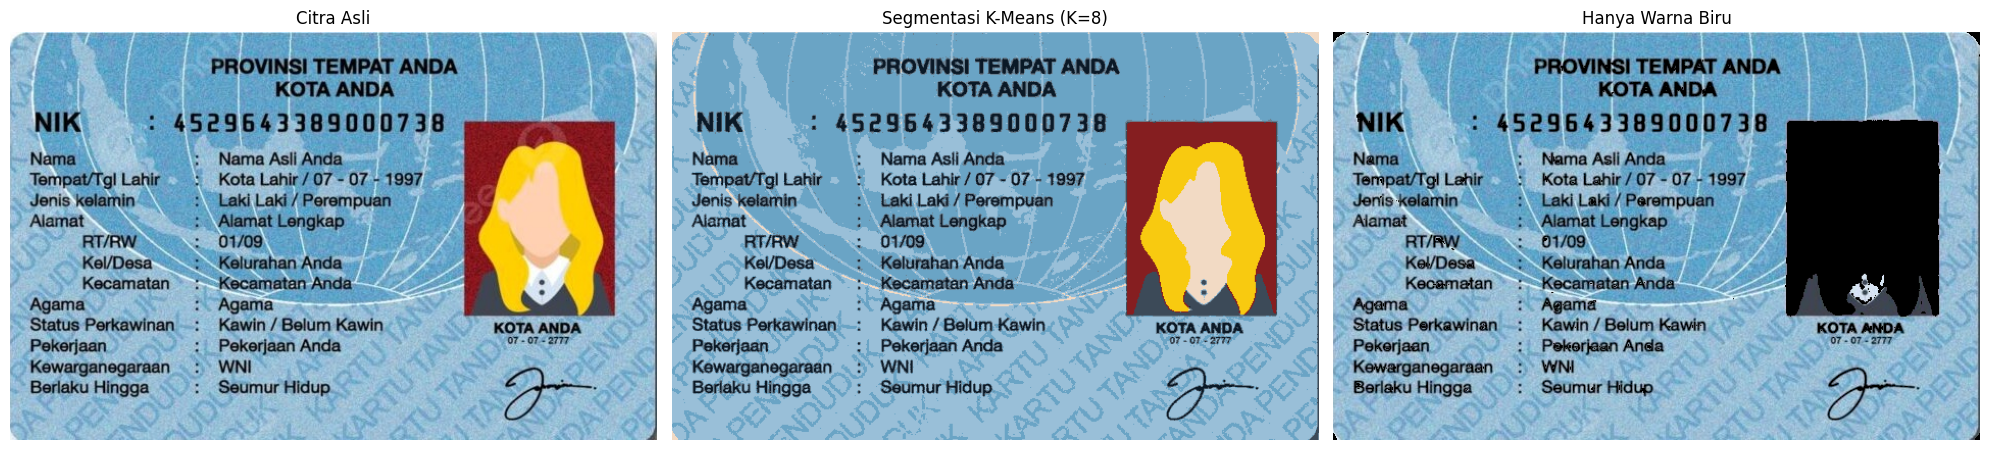

In [ ]:

# 1. Memuat citra KTP dari Google Drive
filename = '/content/drive/MyDrive/ktp_fulani.jpg'
img = cv.imread(filename)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Segmentasi Warna Menggunakan K-Means (K=8)
# Mengubah bentuk citra menjadi array 2D (jumlah piksel x 3 channel warna)
pixel_vals = img_rgb.reshape((-1, 3))
pixel_vals = np.float32(pixel_vals)

# Menentukan kriteria dan jumlah klaster (K = 8)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 8
ret, labels, centers = cv.kmeans(pixel_vals, k, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)

# Mengonversi kembali pusat klaster ke bentuk integer uint8
centers = np.uint8(centers)
segmented_data = centers[labels.flatten()]
segmented_image = segmented_data.reshape(img_rgb.shape)

# 3. Filter Menampilkan Warna Biru Saja Berdasarkan HSV
# Konversi citra asli dari RGB ke HSV
hsv_image = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)
H = hsv_image[:, :, 0]
S = hsv_image[:, :, 1]
V = hsv_image[:, :, 2]

# Menentukan kelompok warna biru sesuai ketentuan soal
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

# Membuat mask untuk warna biru
mask = np.zeros(img_rgb.shape[:2], dtype=np.uint8)
mask[kelompok_biru] = 255

# Menerapkan mask ke citra asli (latar belakang selain biru akan diubah jadi hitam)
hanya_biru = cv.bitwise_and(img_rgb, img_rgb, mask=mask)

# 4. Visualisasi Hasil dalam 3 Kolom (Citra Asli, Segmentasi K-Means, Hanya Warna Biru)
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [img_rgb, segmented_image, hanya_biru]

plt.figure(figsize=(20, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Tugas kelompok D2

In [ ]:
!apt-get -qq update

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
!apt-get -qq install tesseract-ocr tesseract-ocr-ind

Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [ ]:
!pip install tesseract

In [ ]:
!pip install pytesseract

--- Hasil OCR Citra Berwarna ---
—— PROVINSI JAWA TIMUR 1

FN KABUPATEN PASURUAN 2
NIK 34514102208059004
Nama ACHMAD ANVAL ADHIEM ALLAIN :
TempatTgi Lahir “PASURUAN. 22-08-2005 :
Jetis kelamin -LAKHAKI Gol- Darah "3 ' 3

3 Alamat : U


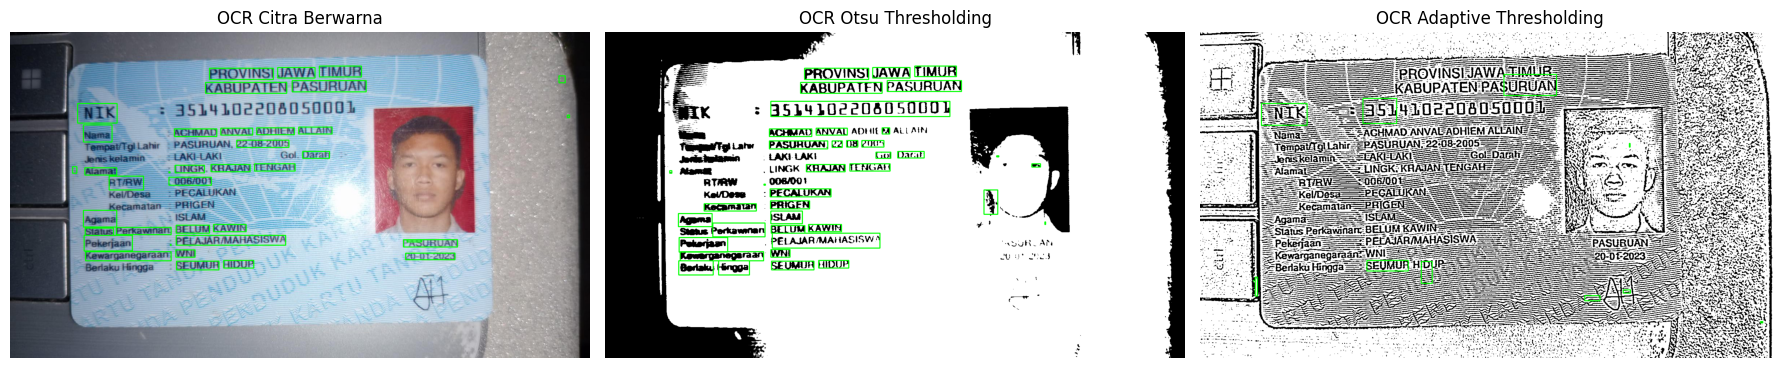

In [ ]:
import pytesseract

# 1. Menyiapkan Citra: Citra Asli, Otsu Thresholding, dan Adaptive Thresholding
# Pastikan path file sesuai dengan direktori Anda (misal menggunakan gambar KTP)
filename = '/content/drive/MyDrive/KTP.jpg'
img_color = cv.imread(filename)
img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

# Ubah ke Grayscale untuk metode thresholding
img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# A. Otsu Thresholding Manual (dari kode sebelumnya)
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:

        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    if final_thresh != -1:
        final_img[gray > final_thresh] = 255
        final_img[gray < final_thresh] = 0
    return final_img

img_otsu = otsu(blur)

# B. Adaptive Thresholding menggunakan OpenCV
img_adaptive = cv.adaptiveThreshold(
    blur, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY, 11, 2
)

# 2. Pembacaan Teks Menggunakan pytesseract (Bahasa Indonesia / 'ind')
custom_config = r'--oem 3 --psm 6'
text_color = pytesseract.image_to_string(img_rgb, lang='ind', config=custom_config)
text_otsu = pytesseract.image_to_string(img_otsu, lang='ind', config=custom_config)
text_adaptive = pytesseract.image_to_string(img_adaptive, lang='ind', config=custom_config)

print("--- Hasil OCR Citra Berwarna ---")
print(text_color[:200]) # Menampilkan sebagian cuplikan teks

# 3. Menampilkan Area Teks dengan Kotak Hijau (Confidence > 60)
def draw_boxes(image, color_mode='rgb'):
    if color_mode == 'gray':
        img_draw = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
    else:
        img_draw = image.copy()

    data = pytesseract.image_to_data(image, lang='ind', config=custom_config, output_type=pytesseract.Output.DICT)
    n_boxes = len(data['text'])

    for i in range(n_boxes):
        # Filter confidence > 60 dan teks tidak kosong
        conf = int(data['conf'][i])
        text = data['text'][i].strip()
        if conf > 60 and len(text) > 0:
            (x, y, w, h) = (data['left'][i], data['top'][i], data['width'][i], data['height'][i])
            # Gambar kotak hijau
            cv.rectangle(img_draw, (x, y), (x + w, y + h), (0, 255, 0), 2)

    return img_draw

box_color = draw_boxes(img_rgb, 'rgb')
box_otsu = draw_boxes(img_otsu, 'gray')
box_adaptive = draw_boxes(img_adaptive, 'gray')

# Visualisasi Hasil Kotak Hijau OCR
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
titles = ['OCR Citra Berwarna', 'OCR Otsu Thresholding', 'OCR Adaptive Thresholding']
images = [box_color, box_otsu, box_adaptive]

for i in range(3):
    axes[i].imshow(images[i])
    axes[i].set_title(titles[i])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import cv2 as cv
import numpy as np
import pytesseract
import pandas as pd

# 1. Load Citra Asli (Pastikan path sesuai)
filename = '/content/drive/MyDrive/KTP.jpg'
img_color = cv.imread(filename)
img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY) # Untuk Otsu & Adaptive

# Proses Otsu & Adaptive
blur = cv.GaussianBlur(img_rgb, (5, 5), 0)
# Otsu sederhana
_, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
# Adaptive
img_adaptive = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

images = {
    "Berwarna asli": cv.cvtColor(img_color, cv.COLOR_BGR2RGB),
    "Segmentasi Otsu": img_otsu,
    "Segmentasi Adaptive": img_adaptive
}

# 2. Tentukan 10 Kata/Angka Acuan yang ada pada KTP Anda
# Sesuaikan list di bawah ini dengan 10 kata/angka yang benar-benar ada pada gambar KTP Anda
acuan_10_kata = [
    "PROVINSI", "DKI", "JAKARTA", "NIK",
    "Name", "LAKI-LAKI", "AGAMA", "ISLAM",
    "WNI", "SEUMUR"
]

config = r'--oem 3 --psm 6'
hasil_tabel = []

for nama_metode, img in images.items():
    # Ambil data OCR lengkap dengan confidence
    ocr_data = pytesseract.image_to_data(img, lang='ind', config=config, output_type=pytesseract.Output.DICT)

    # Gabungkan semua teks terbaca untuk pengecekan kecocokan
    full_text = " ".join([str(t) for t in ocr_data['text'] if t.strip() != ""])

    # Hitung item acuan yang terbaca tepat
    terbaca_tepat = 0
    for kata in acuan_10_kata:
        if kata.lower() in full_text.lower():
            terbaca_tepat += 1

    kecocokan_pct = (terbaca_tepat / 10) * 100

    # Hitung rata-rata confidence (abaikan nilai -1 atau 0 yang kosong)
    confidences = [int(c) for c in ocr_data['conf'] if int(c) > 0]
    avg_conf = np.mean(confidences) if confidences else 0

    hasil_tabel.append({
        "Citra masukan OCR": nama_metode,
        "Item terbaca tepat": f"{terbaca_tepat} dari 10",
        "Kecocokan (%)": f"{kecocokan_pct:.1f}%",
        "Rata-rata confidence": f"{avg_conf:.2f}%"
    })

# 3. Tampilkan Tabel Hasil
df_laporan = pd.DataFrame(hasil_tabel)
print("\n=== TABEL LAPORAN HASIL PENGUJIAN OCR ===")
print(df_laporan.to_string(index=False))


=== TABEL LAPORAN HASIL PENGUJIAN OCR ===
  Citra masukan OCR Item terbaca tepat Kecocokan (%) Rata-rata confidence
      Berwarna asli          5 dari 10         50.0%               64.18%
    Segmentasi Otsu          6 dari 10         60.0%               63.11%
Segmentasi Adaptive          5 dari 10         50.0%               22.70%
